In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, learning_curve
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

In [ ]:
FILE_PATH = 'Used_Cars_Homework.csv'
data = pd.read_csv(FILE_PATH)
data.head(10)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,16950
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,37335
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,30593
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,22641
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,41672
5,11,89859.0,2.0,120,Hyundai,petrol,automatic,yes,18479
6,6,124854.0,3.0,196,Toyota,diesel,automatic,no,38680
7,4,70952.0,1.8,95,BMW,petrol,automatic,no,40016
8,15,248400.0,1.8,90,Hyundai,hybrid,automatic,no,19668
9,11,153076.0,2.0,140,BMW,hybrid,automatic,no,36190


In [ ]:
data.tail()

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
295,8,103080.0,3.0,206,BMW,petrol,manual,no,46582
296,3,27051.0,NaN,98,BMW,hybrid,automatic,no,40510
297,1,18300.0,1.2,67,Kia,diesel,manual,no,26710
298,11,170764.0,1.6,90,BMW,petrol,manual,no,21582
299,5,103115.0,2.0,141,BMW,diesel,manual,no,36582


In [ ]:
data.sample(3, random_state=42)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
203,2,39196.0,1.4,84,Toyota,NaN,automatic,no,34837
266,3,64641.0,1.8,119,Toyota,diesel,automatic,no,34946
152,4,29240.0,1.8,114,Hyundai,diesel,automatic,no,32214


In [ ]:
print(f"Размер таблицы: {data.shape[0]} строк, {data.shape[1]} столбцов\n")
print("Типы данных:")
print(data.dtypes)
print("\nКоличество пропусков:")
print(data.isna().sum())

Размер таблицы: 300 строк, 9 столбцов

Типы данных:
age_years             int64
mileage_km          float64
engine_l            float64
power_hp              int64
brand                object
fuel_type            object
transmission         object
accident_history     object
price_azn             int64
dtype: object

Количество пропусков:
age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64


In [ ]:
data.describe()

,age_years,mileage_km,engine_l,power_hp,price_azn
count,300.000000,283.000000,284.000000,300.000000,300.000000
mean,7.850000,118302.176678,1.901761,123.270000,27806.573333
std,4.147066,73652.009931,0.581484,39.903861,9772.778467
min,1.000000,8659.000000,1.200000,57.000000,3805.000000
25%,4.000000,54862.500000,1.400000,93.000000,21865.500000
50%,8.000000,112308.000000,1.800000,113.000000,27458.500000
75%,11.000000,166869.500000,2.500000,151.250000,34844.750000
max,15.000000,334305.000000,3.000000,218.000000,51396.000000


In [ ]:
min_price = data['price_azn'].min()
max_price = data['price_azn'].max()
mean_price = data['price_azn'].mean()

print(f"Минимальная стоимость: {min_price} AZN")
print(f"Максимальная стоимость: {max_price} AZN")
print(f"Средняя стоимость: {mean_price:.2f} AZN")

Минимальная стоимость: 3805 AZN
Максимальная стоимость: 51396 AZN
Средняя стоимость: 27806.57 AZN


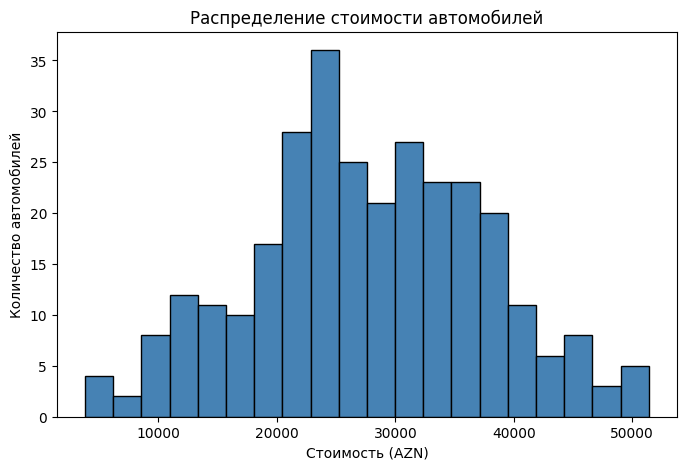

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(data['price_azn'], bins=20, color='steelblue', edgecolor='black')
plt.title('Распределение стоимости автомобилей')
plt.xlabel('Стоимость (AZN)')
plt.ylabel('Количество автомобилей')
plt.show()

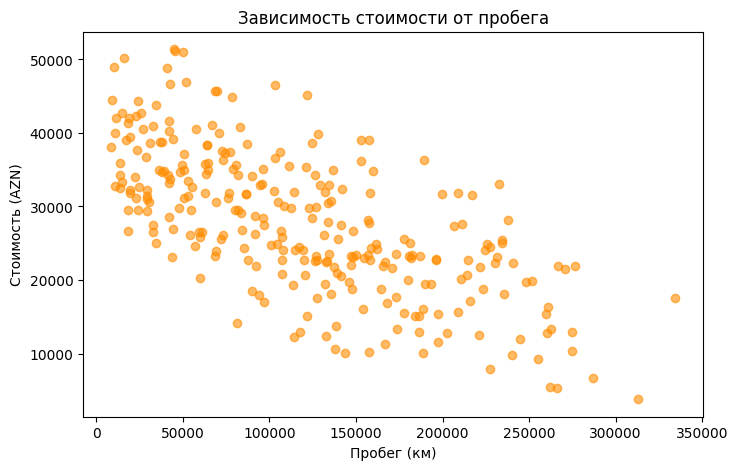

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(data['mileage_km'], data['price_azn'], alpha=0.6, color='darkorange')
plt.title('Зависимость стоимости от пробега')
plt.xlabel('Пробег (км)')
plt.ylabel('Стоимость (AZN)')
plt.show()

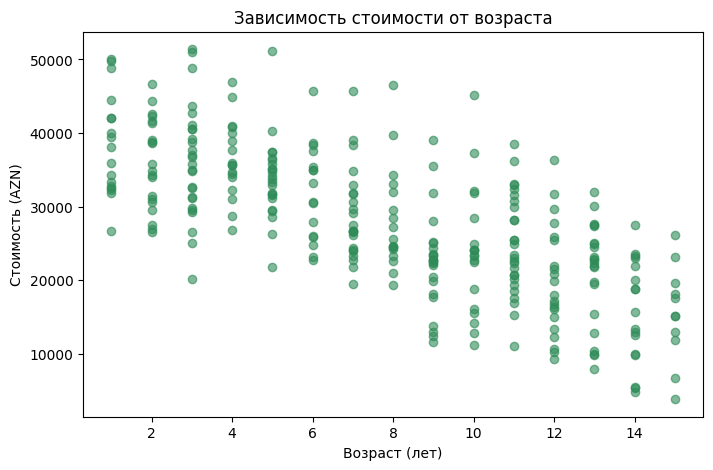

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(data['age_years'], data['price_azn'], alpha=0.6, color='seagreen')
plt.title('Зависимость стоимости от возраста')
plt.xlabel('Возраст (лет)')
plt.ylabel('Стоимость (AZN)')
plt.show()

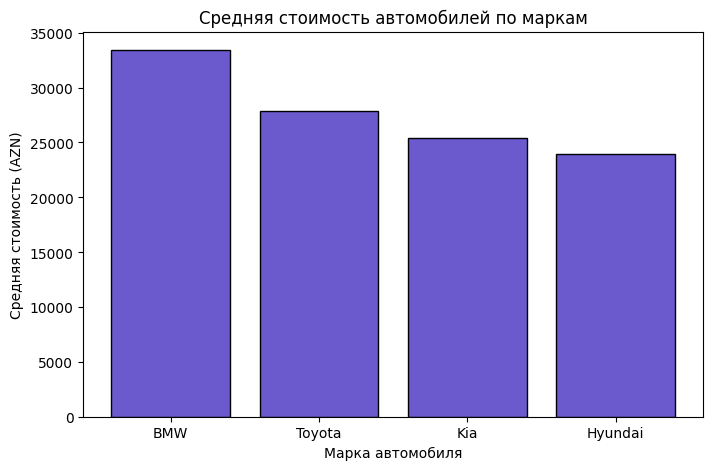

In [ ]:
brand_avg_price = data.groupby('brand')['price_azn'].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(brand_avg_price.index, brand_avg_price.values, color='slateblue', edgecolor='black')
plt.title('Средняя стоимость автомобилей по маркам')
plt.xlabel('Марка автомобиля')
plt.ylabel('Средняя стоимость (AZN)')
plt.show()

In [ ]:
data_fe = data.copy()
data_fe['mileage_per_year'] = data_fe['mileage_km'] / np.where(
    data_fe['age_years'] > 0, data_fe['age_years'], 1
)

target_col = 'price_azn'
X = data_fe.drop(columns=[target_col])
y = data_fe[target_col]

In [ ]:
numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

In [ ]:
numeric_features

['age_years', 'mileage_km', 'engine_l', 'power_hp', 'mileage_per_year']

In [ ]:
categorical_features

['brand', 'fuel_type', 'transmission', 'accident_history']

In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
    ]
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Обучающая выборка: {X_train.shape[0]} строк, {X_train.shape[1]} признаков")
print(f"Тестовая выборка: {X_test.shape[0]} строк, {X_test.shape[1]} признаков")

Обучающая выборка: 240 строк, 9 признаков
Тестовая выборка: 60 строк, 9 признаков


In [ ]:
reg = DecisionTreeRegressor(random_state=42, criterion='squared_error')

pipe = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('tree', reg)
    ]
)

param_grid = {
    'tree__max_depth': [3, 5, 7, None],
    'tree__min_samples_split': [2, 5, 10],
    'tree__min_samples_leaf': [1, 3, 5, 10],
}

In [ ]:
cv = KFold(n_splits=5, random_state=42, shuffle=True)
grid_search = GridSearchCV(pipe, param_grid, cv=cv, scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
grid_search.best_params_

{'tree__max_depth': 7,
 'tree__min_samples_leaf': 3,
 'tree__min_samples_split': 10}

In [ ]:
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

y_pred = best_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse_val = rmse(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'''
Best params: {grid_search.best_params_}
MAE:  {mae:.3f}
MSE:  {mse:.3f}
RMSE: {rmse_val:.3f}
R2:   {r2:.4f}
''')


Best params: {'tree__max_depth': 7, 'tree__min_samples_leaf': 3, 'tree__min_samples_split': 10}
MAE:  3676.451
MSE:  19793754.209
RMSE: 4449.017
R2:   0.8064



In [ ]:
comparison_df = pd.DataFrame({
    'Реальная стоимость (AZN)': y_test.values,
    'Прогноз модели (AZN)': np.round(y_pred, 2),
    'Абсолютная ошибка (AZN)': np.round(np.abs(y_test.values - y_pred), 2)
}, index=y_test.index)

comparison_df.head(10)

,Реальная стоимость (AZN),Прогноз модели (AZN),Абсолютная ошибка (AZN)
203,34837,28346.50,6490.50
266,34946,27262.00,7684.00
152,32214,31680.89,533.11
9,36190,36830.89,640.89
233,25000,28346.50,3346.50
226,26522,31826.75,5304.75
196,22711,20130.78,2580.22
109,33061,36830.89,3769.89
5,18479,14429.86,4049.14
175,25003,28945.62,3942.62


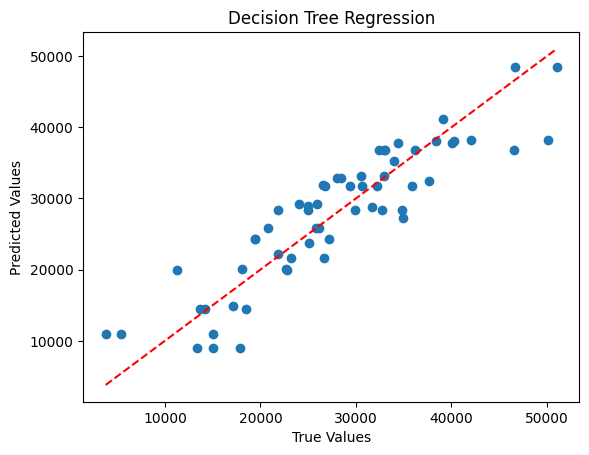

In [ ]:
plt.figure()
plt.scatter(y_test, y_pred)
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.title('Decision Tree Regression')
high = max(y_test.max(), y_pred.max())
low = min(y_test.min(), y_pred.min())
plt.plot([low, high], [low, high], 'r--')
plt.show()

In [ ]:
oh = None
if categorical_features:
    oh = best_model.named_steps['preprocessor'].transformers_[1][1].named_steps['onehot']
num_names = numeric_features
cat_names = oh.get_feature_names_out(categorical_features).tolist() if oh is not None else []
feature_names = num_names + cat_names
feature_names

['age_years',
 'mileage_km',
 'engine_l',
 'power_hp',
 'mileage_per_year',
 'brand_BMW',
 'brand_Hyundai',
 'brand_Kia',
 'brand_Toyota',
 'fuel_type_diesel',
 'fuel_type_hybrid',
 'fuel_type_petrol',
 'transmission_automatic',
 'transmission_manual',
 'accident_history_no',
 'accident_history_yes']

In [ ]:
importances = best_model.named_steps['tree'].feature_importances_
imp_df = (pd.DataFrame(
    {
        'feature': feature_names if len(feature_names) == len(importances) else [f'feature_{i}' for i in range(len(importances))],
        'importance': importances
    }
).sort_values(by='importance', ascending=False).head(10)
)
imp_df

,feature,importance
0,age_years,0.557521
3,power_hp,0.224994
5,brand_BMW,0.118669
1,mileage_km,0.040824
10,fuel_type_hybrid,0.016696
4,mileage_per_year,0.014240
2,engine_l,0.010459
14,accident_history_no,0.006397
8,brand_Toyota,0.005251
7,brand_Kia,0.004309


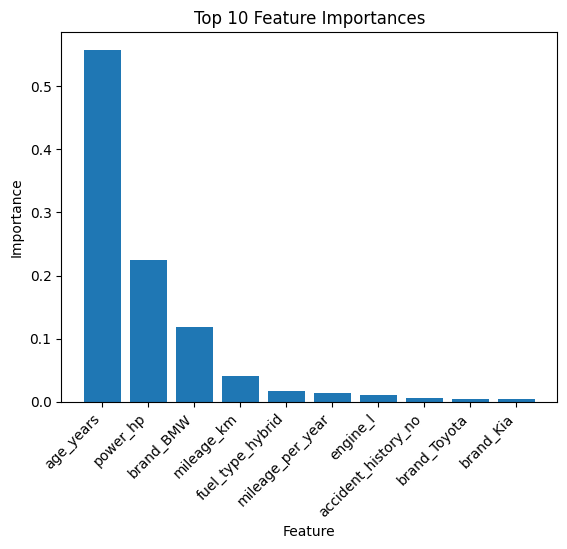

In [ ]:
plt.figure()
plt.bar(imp_df['feature'], imp_df['importance'])
plt.title('Top 10 Feature Importances')
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.xticks(rotation=45, ha='right')
plt.show()

,Количество примеров,Training R2,CV R2,Разница (Train - CV)
0,19,0.7432,0.2956,0.4477
1,43,0.8576,0.4470,0.4106
2,68,0.8664,0.5264,0.3400
3,93,0.8783,0.5984,0.2799
4,117,0.8836,0.5957,0.2879
5,142,0.8939,0.5920,0.3019
6,167,0.9025,0.6517,0.2508
7,192,0.9130,0.7047,0.2083


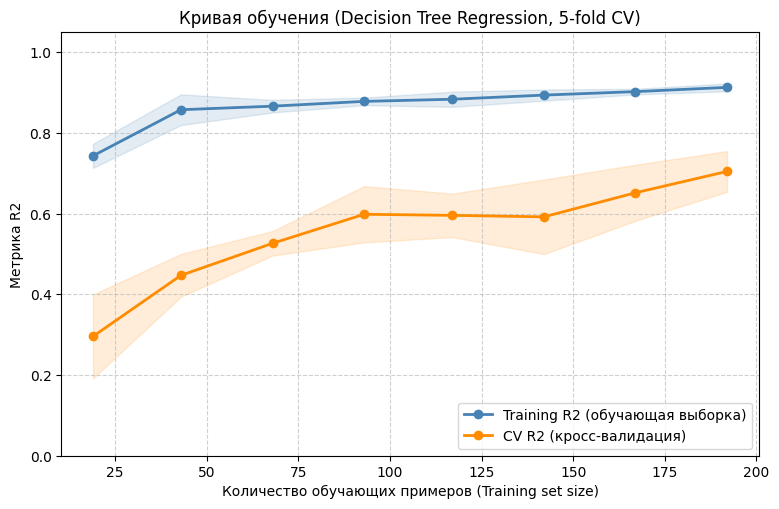

In [ ]:
train_sizes, train_scores, test_scores = learning_curve(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring='r2',
    train_sizes=np.linspace(0.1, 1.0, 8),
    shuffle=True,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
test_mean = test_scores.mean(axis=1)
test_std = test_scores.std(axis=1)

lc_df = pd.DataFrame({
    'Количество примеров': train_sizes,
    'Training R2': np.round(train_mean, 4),
    'CV R2': np.round(test_mean, 4),
    'Разница (Train - CV)': np.round(train_mean - test_mean, 4)
})
display(lc_df)

plt.figure(figsize=(9, 5.5))
plt.plot(train_sizes, train_mean, 'o-', color='steelblue', linewidth=2, label='Training R2 (обучающая выборка)')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='steelblue')

plt.plot(train_sizes, test_mean, 'o-', color='darkorange', linewidth=2, label='CV R2 (кросс-валидация)')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='darkorange')

plt.title('Кривая обучения (Decision Tree Regression, 5-fold CV)')
plt.xlabel('Количество обучающих примеров (Training set size)')
plt.ylabel('Метрика R2')
plt.ylim(0.0, 1.05)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.show()

In [ ]:
new_cars = pd.DataFrame({
    'age_years': [5, 10, 3],
    'mileage_km': [75000, 180000, 40000],
    'engine_l': [1.6, 2.0, 2.5],
    'power_hp': [110, 140, 170],
    'brand': ['Toyota', 'Hyundai', 'BMW'],
    'fuel_type': ['petrol', 'diesel', 'petrol'],
    'transmission': ['automatic', 'manual', 'automatic'],
    'accident_history': ['no', 'yes', 'no']
})

new_cars_fe = new_cars.copy()
new_cars_fe['mileage_per_year'] = new_cars_fe['mileage_km'] / np.where(
    new_cars_fe['age_years'] > 0, new_cars_fe['age_years'], 1
)

predicted_prices = best_model.predict(new_cars_fe)

predictions_table = new_cars.copy()
predictions_table['mileage_per_year'] = new_cars_fe['mileage_per_year'].round(1)
predictions_table['Прогноз стоимости (AZN)'] = np.round(predicted_prices, 2)

display(predictions_table)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,mileage_per_year,Прогноз стоимости (AZN)
0,5,75000,1.6,110,Toyota,petrol,automatic,no,15000.0,28346.50
1,10,180000,2.0,140,Hyundai,diesel,manual,yes,18000.0,23735.33
2,3,40000,2.5,170,BMW,petrol,automatic,no,13333.3,48427.50
